Loading the files:

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


products = pd.read_csv("olist_products_dataset.csv")
translation = pd.read_csv("product_category_name_translation.csv")

products_clean = products.copy()
translation_clean = translation.copy()

validation function:

In [2]:
print("PRODUCTS SHAPE:", products.shape)
print("TRANSLATION SHAPE:", translation.shape)

print("\nMISSING VALUES")
missing = products.isnull().sum().to_frame("count")
missing["percent"] = (missing["count"] / len(products) * 100).round(2)
print(missing[missing["count"] > 0])

print("\nDUPLICATES")
print("full duplicate rows:", products.duplicated().sum())
print("duplicate product_id:", products["product_id"].duplicated().sum())
print("duplicate categories in translation:", translation["product_category_name"].duplicated().sum())

print("\nID FORMAT")
print("ids that are not 32 characters:", (products["product_id"].str.len() != 32).sum())

print("\nTEXT PROBLEMS")
cat = products["product_category_name"].dropna()
print("categories with extra spaces:", (cat != cat.str.strip()).sum())
print("categories with uppercase:", (cat != cat.str.lower()).sum())

print("\nCATEGORIES MISSING FROM TRANSLATION")
print(set(cat) - set(translation["product_category_name"]))

print("\nZERO OR NEGATIVE VALUES")
num = products.select_dtypes("number")
zeros = (num <= 0).sum()
print(zeros[zeros > 0])

print("\nOUTLIERS (IQR rule)")
for c in num.columns:
    q1, q3 = num[c].quantile(0.25), num[c].quantile(0.75)
    iqr = q3 - q1
    n = ((num[c] < q1 - 1.5 * iqr) | (num[c] > q3 + 1.5 * iqr)).sum()
    print(c, n)

print("\nROWS WITH 4 OR MORE MISSING VALUES")
print(products[products.isnull().sum(axis=1) >= 4].shape[0])

print("\nMIN / MEDIAN / MAX")
print(num.describe().T[["min", "50%", "max"]])

PRODUCTS SHAPE: (32951, 9)
TRANSLATION SHAPE: (71, 2)

MISSING VALUES
                            count  percent
product_category_name         610     1.85
product_name_lenght           610     1.85
product_description_lenght    610     1.85
product_photos_qty            610     1.85
product_weight_g                2     0.01
product_length_cm               2     0.01
product_height_cm               2     0.01
product_width_cm                2     0.01

DUPLICATES
full duplicate rows: 0
duplicate product_id: 0
duplicate categories in translation: 0

ID FORMAT
ids that are not 32 characters: 0

TEXT PROBLEMS
categories with extra spaces: 0
categories with uppercase: 0

CATEGORIES MISSING FROM TRANSLATION
{'portateis_cozinha_e_preparadores_de_alimentos', 'pc_gamer'}

ZERO OR NEGATIVE VALUES
product_weight_g    4
dtype: int64

OUTLIERS (IQR rule)
product_name_lenght 290
product_description_lenght 2078
product_photos_qty 849
product_weight_g 4551
product_length_cm 1380
product_height_cm 18

clean the text




In [3]:
products["product_category_name"] = products["product_category_name"].str.strip().str.lower()
translation["product_category_name"] = translation["product_category_name"].str.strip().str.lower()
translation["product_category_name_english"] = translation["product_category_name_english"].str.strip().str.lower()

fix column names and the translation file

In [4]:
products = products.rename(columns={
    "product_name_lenght": "product_name_length",
    "product_description_lenght": "product_description_length"
})

new_rows = pd.DataFrame({
    "product_category_name": ["pc_gamer", "portateis_cozinha_e_preparadores_de_alimentos"],
    "product_category_name_english": ["pc_gamer", "portable_kitchen_and_food_preparers"]
})
translation = pd.concat([translation, new_rows], ignore_index=True)
translation = translation.drop_duplicates(subset="product_category_name")

handle the missing categories

In [5]:
products["category_was_missing"] = products["product_category_name"].isnull()
products["product_category_name"] = products["product_category_name"].fillna("unknown")

drop the rows with no size

In [6]:
products = products.dropna(subset=["product_length_cm", "product_height_cm", "product_width_cm"])

handle the weight of 0

In [7]:
products["product_weight_g"] = products["product_weight_g"].where(products["product_weight_g"] > 0)

fill the missing numbers using the category

In [8]:
fill_cols = ["product_name_length", "product_description_length", "product_photos_qty", "product_weight_g"]

for c in fill_cols:
    products[c] = products[c].fillna(products.groupby("product_category_name")[c].transform("median"))
    products[c] = products[c].fillna(products[c].median())

fix the data types and add a useful column

In [9]:
int_cols = ["product_name_length", "product_description_length", "product_photos_qty"]
products[int_cols] = products[int_cols].round().astype(int)

products["product_volume_cm3"] = products["product_length_cm"] * products["product_height_cm"] * products["product_width_cm"]

products = products.reset_index(drop=True)

check the result

In [10]:
print(products.shape, translation.shape)
print("missing values:", products.isnull().sum().sum())
print("zero or negative values:", (products.select_dtypes("number") <= 0).sum().sum())
print(products.dtypes)
print("flag count:", products["category_was_missing"].sum())
print([c for c in products.columns if "volume" in c])

(32949, 11) (73, 2)
missing values: 0
zero or negative values: 0
product_id                     object
product_category_name          object
product_name_length             int64
product_description_length      int64
product_photos_qty              int64
product_weight_g              float64
product_length_cm             float64
product_height_cm             float64
product_width_cm              float64
category_was_missing             bool
product_volume_cm3            float64
dtype: object
flag count: 609
['product_volume_cm3']


Validate and export

In [11]:
os.makedirs("cleaned_data", exist_ok=True)

products.to_csv("cleaned_data/olist_products_clean.csv", index=False)
translation.to_csv("cleaned_data/product_category_name_translation_clean.csv", index=False)

print(os.listdir("cleaned_data"))

['olist_products_clean.csv', 'product_category_name_translation_clean.csv']


## Outlier detection, correlation matrix and PCA

### Outlier detection (IQR rule, before and after log transform)


,raw,after_log
product_name_length,290,290
product_description_length,2174,229
product_photos_qty,849,114
product_weight_g,4551,6
product_length_cm,1380,0
product_height_cm,1892,130
product_width_cm,912,72


rows with at least one outlier: 8350 -> 830 out of 32949


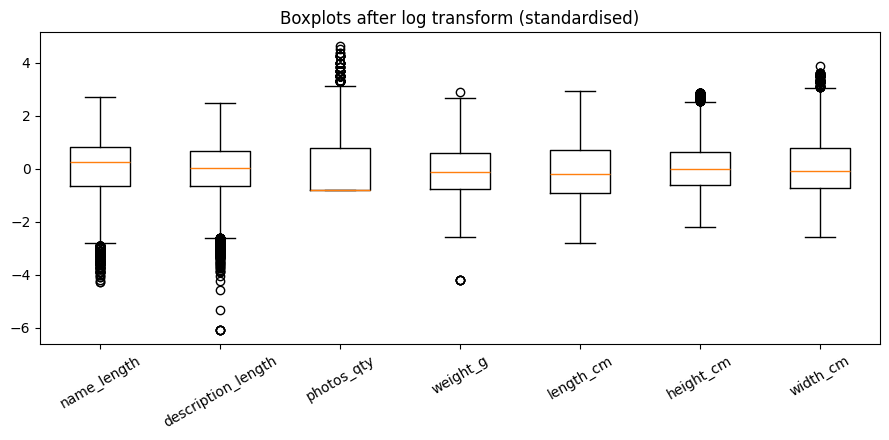

In [12]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import seaborn as sns

num_cols = ["product_name_length", "product_description_length", "product_photos_qty",
            "product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm"]
skewed_cols = num_cols[1:]   # everything except name length

# log transform of the skewed columns (used for outliers, correlation and PCA)
X_log = products[num_cols].copy()
X_log[skewed_cols] = np.log1p(X_log[skewed_cols])

def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)

raw_out = products[num_cols].apply(iqr_outliers)
log_out = X_log.apply(iqr_outliers)

display(pd.DataFrame({"raw": raw_out.sum(), "after_log": log_out.sum()}))
print("rows with at least one outlier:", raw_out.any(axis=1).sum(), "->", log_out.any(axis=1).sum(),
      "out of", len(products))

Z = (X_log - X_log.mean()) / X_log.std()
plt.figure(figsize=(9, 4.5))
plt.boxplot(Z.values)
plt.xticks(range(1, len(num_cols) + 1), [c.replace("product_", "") for c in num_cols], rotation=30)
plt.title("Boxplots after log transform (standardised)")
plt.tight_layout(); plt.show()

### Correlation matrix

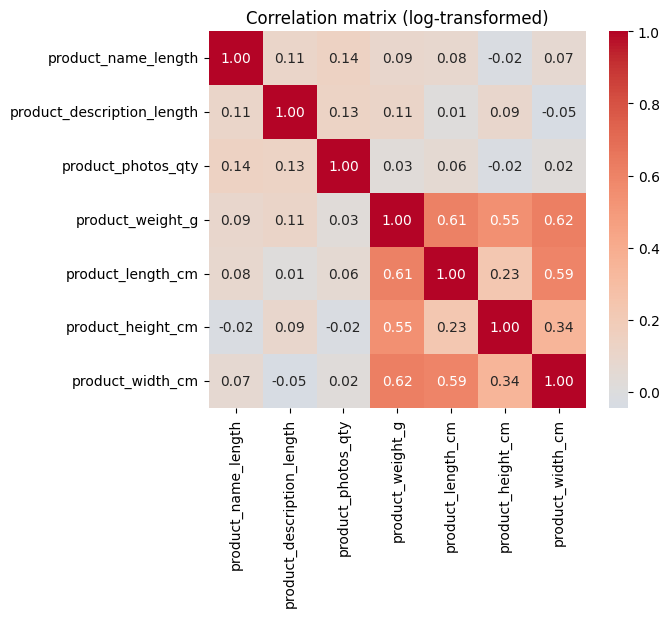

In [13]:
plt.figure(figsize=(7, 6))
sns.heatmap(X_log.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation matrix (log-transformed)")
plt.tight_layout(); plt.show()

### PCA extraction


In [14]:
X_scaled = StandardScaler().fit_transform(X_log)

pca = PCA()
scores = pca.fit_transform(X_scaled)

var = pd.DataFrame({
    "PC": [f"PC{i+1}" for i in range(len(num_cols))],
    "eigenvalue": pca.explained_variance_.round(2),
    "variance_%": (pca.explained_variance_ratio_ * 100).round(1),
    "cumulative_%": (np.cumsum(pca.explained_variance_ratio_) * 100).round(1),
})
display(var)

loadings = pd.DataFrame(pca.components_.T, index=num_cols,
                        columns=[f"PC{i+1}" for i in range(len(num_cols))])
display(loadings.iloc[:, :3].round(2))

,PC,eigenvalue,variance_%,cumulative_%
0,PC1,2.52,36.0,36.0
1,PC2,1.24,17.7,53.7
2,PC3,0.99,14.1,67.8
3,PC4,0.86,12.3,80.1
4,PC5,0.72,10.3,90.4
5,PC6,0.39,5.6,96.0
6,PC7,0.28,4.0,100.0


,PC1,PC2,PC3
product_name_length,0.09,0.56,-0.40
product_description_length,0.06,0.55,0.67
product_photos_qty,0.04,0.60,-0.21
product_weight_g,0.56,-0.01,0.09
product_length_cm,0.50,-0.02,-0.26
product_height_cm,0.40,-0.10,0.47
product_width_cm,0.51,-0.11,-0.21


### Scree plot and loadings

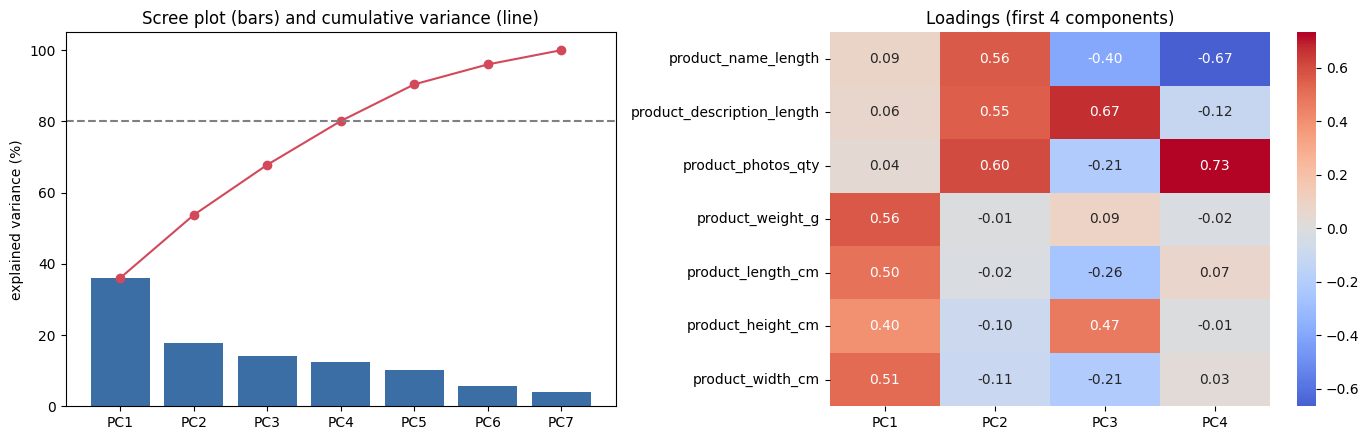

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].bar(var["PC"], var["variance_%"], color="#3b6ea5")
axes[0].plot(var["PC"], var["cumulative_%"], "o-", color="#d1495b")
axes[0].axhline(80, ls="--", color="grey")
axes[0].set_title("Scree plot (bars) and cumulative variance (line)")
axes[0].set_ylabel("explained variance (%)")

sns.heatmap(loadings.iloc[:, :4], annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Loadings (first 4 components)")

plt.tight_layout(); plt.show()

### Projection on PC1 / PC2

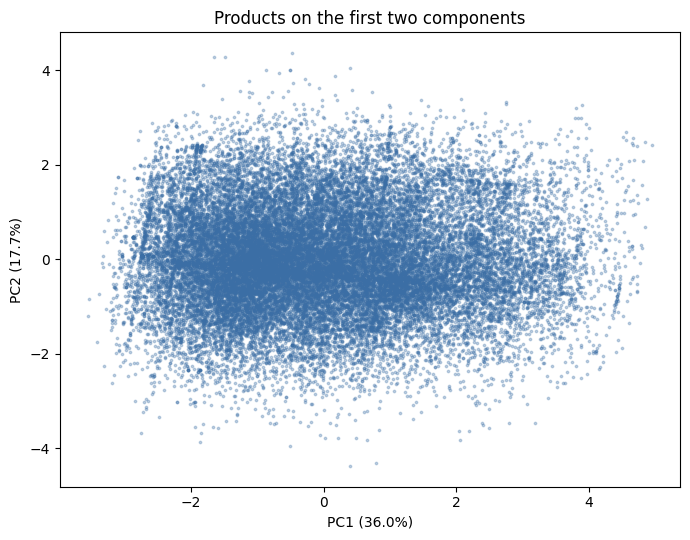

In [16]:
plt.figure(figsize=(7, 5.5))
plt.scatter(scores[:, 0], scores[:, 1], s=3, alpha=0.3, color="#3b6ea5")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
plt.title("Products on the first two components")
plt.tight_layout(); plt.show()